# 01. Los dos datasets: cadena de toros y superficies conexas

En la revisión de avances la red se entrenó con el dataset de 300 superficies ampliado a 2100. Al mirar las mallas por dentro apareció una inconsistencia: lo que el dataset llama *género g* son **g toros sueltos**, no una superficie de género g. Una superficie de género g es **una sola pieza** con g huecos y su característica de Euler es 2 − 2g. En el dataset original cada pieza es un toro, así que la característica de Euler de la malla siempre da 0 aunque el metadata diga 2 − 2g.

Por eso el proyecto ahora tiene dos datasets, generados con el mismo código y las mismas deformaciones:

| dataset | qué es una superficie de etiqueta g | piezas | característica de Euler |
|---|---|---|---|
| `cadena` | g toros sueltos en fila (método original) | g | 0 |
| `conexa` | g toros **pegados** en una sola superficie | 1 | 2 − 2g |

En este cuaderno se comprueba esa diferencia con números y se miran las imágenes que recibe la red.

In [1]:
import sys  # para agregar src al camino de búsqueda
from pathlib import Path  # rutas que sirven en cualquier sistema operativo

import matplotlib.pyplot as plt  # gráficos
import numpy as np  # arreglos numéricos
import pandas as pd  # tablas

ROOT = Path.cwd().parent  # carpeta raíz del repositorio (este cuaderno vive en notebooks/)
sys.path.insert(0, str(ROOT / "src"))  # permite importar genuscnn sin instalarlo

from genuscnn import data as D  # datos del proyecto
from genuscnn import geometry as G  # geometría del proyecto
from genuscnn.generate import build_family  # construye la malla base de una familia
from genuscnn.plots import plot_gallery  # galería de imágenes

## 1. Cargar los dos datasets

Los datasets se generan con `python scripts/generate_dataset.py`. Cada uno tiene 6 géneros, 35 familias por género y 10 muestras por familia: 2100 superficies de 3000 puntos.

In [2]:
manifests, clouds = {}, {}  # tabla y nubes de cada dataset
for variant in ("cadena", "conexa"):  # recorre los dos datasets
    manifests[variant] = D.split_by_family(D.build_manifest(ROOT / "data" / variant / "topology_dataset"))  # tabla con el split por familia
    clouds[variant] = D.load_clouds(manifests[variant])  # nubes en memoria
pd.concat({v: m.groupby("genus").size() for v, m in manifests.items()}, axis=1)  # superficies por género en cada dataset

,cadena,conexa
genus,,
0,350,350
1,350,350
2,350,350
3,350,350
4,350,350
5,350,350


In [3]:
manifests["conexa"].groupby(["genus", "split"])["group"].nunique().unstack()  # familias por género y split: 25 train, 5 validation, 5 test

split,test,train,val
genus,,,
0,5,25,5
1,5,25,5
2,5,25,5
3,5,25,5
4,5,25,5
5,5,25,5


## 2. La topología medida en las mallas

Para cada género se reconstruye la malla base de una familia y se mide:

- **piezas:** componentes conexas de la malla;
- **χ:** característica de Euler, V − E + F;
- **cerrada:** cada arista toca exactamente dos caras, o sea que no hay bordes;
- **huecos:** la suma de los géneros de todas las piezas, (2·piezas − χ) / 2.

Antes de medir se sueldan los vértices repetidos. En el dataset original la esfera tenía los polos duplicados y por eso su χ calculado daba 0 en lugar de 2.

In [4]:
rows = []  # filas de la tabla
for variant in ("cadena", "conexa"):  # recorre los dos datasets
    for g in range(6):  # recorre los géneros
        V, F, topology = build_family(variant, g, family=7)  # malla base de la familia 07 y su topología
        rows.append(dict(dataset=variant, etiqueta=g, vertices=len(V), piezas=topology["components"], chi=topology["euler"], cerrada=topology["closed"], huecos=topology["holes"], chi_de_genero_g=2 - 2 * g))  # fila
topology_table = pd.DataFrame(rows).set_index(["dataset", "etiqueta"])  # tabla ordenada por dataset y etiqueta
topology_table  # muestra la tabla

vertices  piezas  chi  cerrada  huecos  chi_de_genero_g
dataset etiqueta                                                         
cadena  0             3150       1    2     True       0                2
        1             3150       1    0     True       1                0
        2             6300       2    0     True       2               -2
        3             9450       3    0     True       3               -4
        4            12600       4    0     True       4               -6
        5            15750       5    0     True       5               -8
conexa  0             6084       1    2     True       0                2
        1             2492       1    0     True       1                0
        2             6764       1   -2     True       2               -2
        3            11646       1   -4     True       3               -4
        4             7986       1   -6     True       4               -6
        5            13242       1   -8     True       5               -8

En `cadena` la etiqueta coincide con el número de piezas y χ siempre es 0. En `conexa` siempre hay una sola pieza y χ = 2 − 2g, que es lo que debe cumplir una superficie de género g. Las dos tienen g huecos, así que la etiqueta es la misma; lo que cambia es si además se puede acertar contando piezas.

In [5]:
checks = []  # resultado de revisar todas las familias conexas
for g in range(6):  # recorre los géneros
    for family in range(35):  # recorre las 35 familias
        _, _, topology = build_family("conexa", g, family)  # topología de la familia
        checks.append(topology["components"] == 1 and topology["closed"] and topology["euler"] == 2 - 2 * g)  # ¿es de género g?
print("familias conexas con género correcto:", sum(checks), "de", len(checks))  # deben ser todas

familias conexas con género correcto: 210 de 210


## 3. Cómo se construye una superficie conexa

Cada toro se describe con su función de distancia (negativa adentro del tubo, positiva afuera). Los toros se colocan en fila de modo que los tubos vecinos se solapan, y los campos se unen con un **mínimo suave**, que redondea la junta. La superficie es el nivel cero de ese campo y la malla se saca con *marching cubes*. Después se aplican las mismas tres deformaciones del dataset original: una deformación suave con ondas, un escalado distinto en cada eje y una rotación al azar.

Abajo se ve una familia de género 3 de cada dataset.

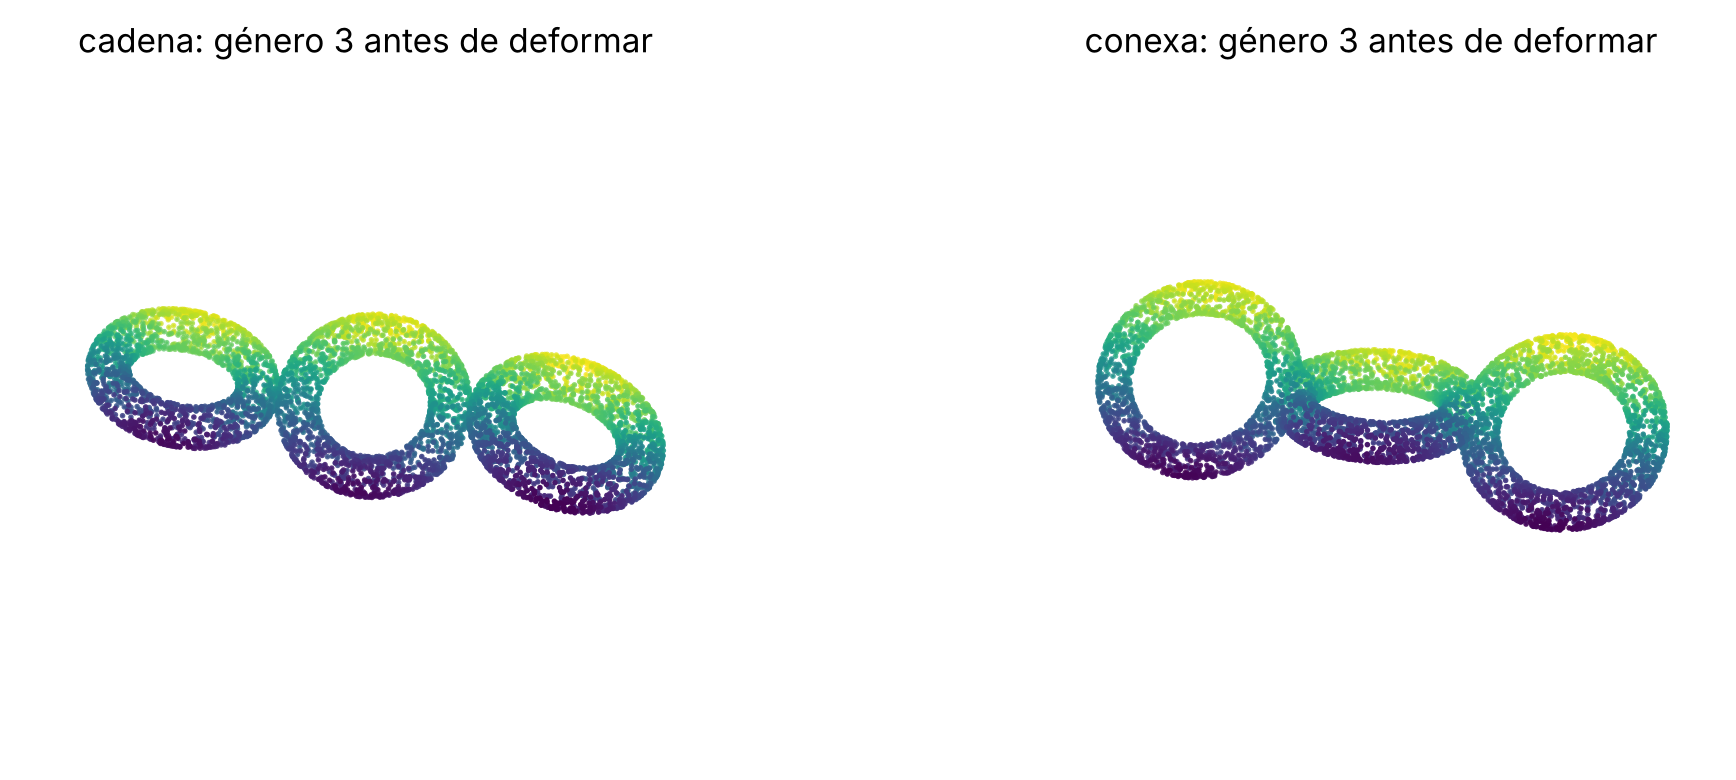

In [6]:
fig = plt.figure(figsize=(11, 4))  # figura con dos paneles 3d
for k, variant in enumerate(("cadena", "conexa")):  # un panel por dataset
    V, F, _ = build_family(variant, 3, family=7)  # malla base de género 3
    X = G.sample_surface(V, F, 6000, np.random.default_rng(0))  # nube de 6000 puntos sin deformar
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")  # panel 3d
    ax.scatter(X[:, 0], X[:, 1], X[:, 2], s=1, c=X[:, 1], cmap="viridis")  # puntos coloreados por profundidad
    ax.set_box_aspect(np.ptp(X, axis=0))  # misma escala en los tres ejes
    ax.view_init(elev=55, azim=-80)  # punto de vista
    ax.set_axis_off()  # sin ejes
    ax.set_title(f"{variant}: género 3 antes de deformar")  # título
plt.tight_layout()  # ajusta los espacios
plt.show()  # muestra la figura

## 4. Las imágenes que ve la red

Cada nube se centra, se escala para caber en la esfera de radio 1, se rota al azar y se proyecta a una imagen de 64 × 64 en escala de grises donde el tono es la profundidad. Cada fila es un género; las cinco columnas de la izquierda son `cadena` y las cinco de la derecha son `conexa`.

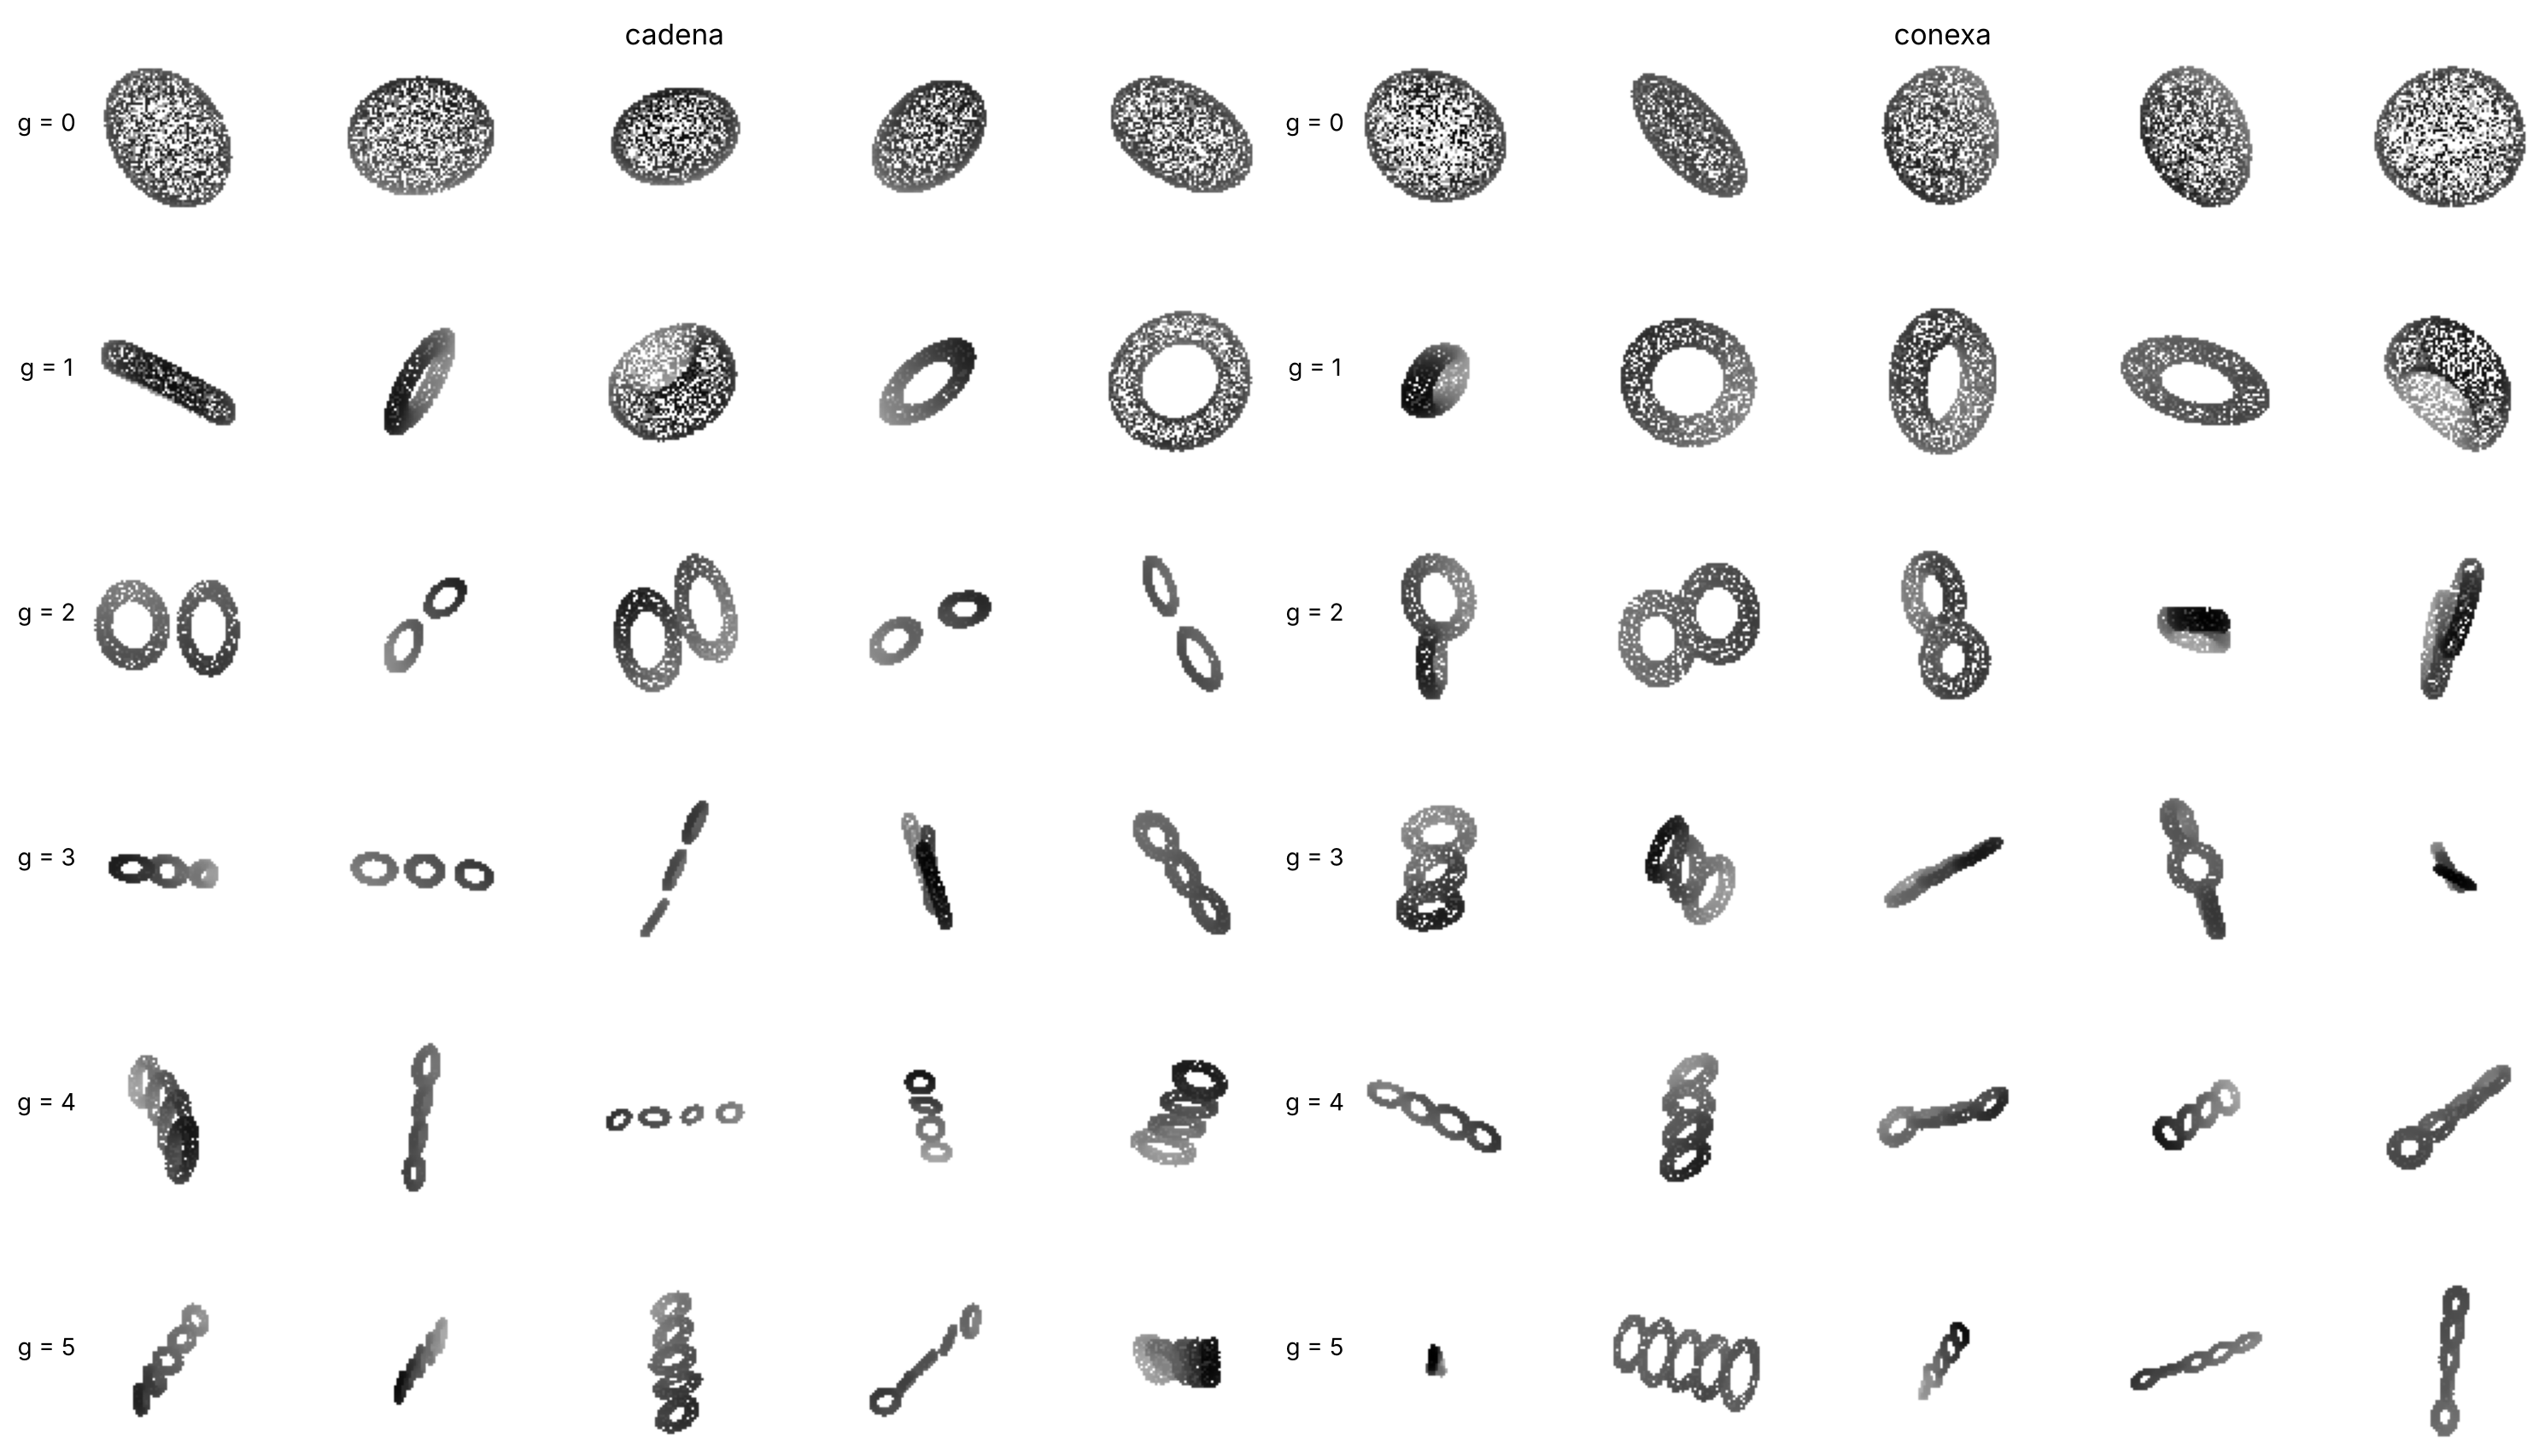

In [7]:
fig = plot_gallery(manifests, clouds, per_variant=5, seed=0)  # galería de los dos datasets
fig.savefig(ROOT / "results" / "figures" / "datasets.png", dpi=150, bbox_inches="tight")  # guarda la figura para el readme
plt.show()  # muestra la figura

## 5. La pista de la tinta

Como todas las nubes se escalan al mismo tamaño, una cadena más larga queda más delgada y pinta menos píxeles. La proporción de píxeles pintados (la *tinta*) baja con el género en los dos datasets. Por eso en los resultados siempre se compara la red contra un modelo que solo mira la tinta.

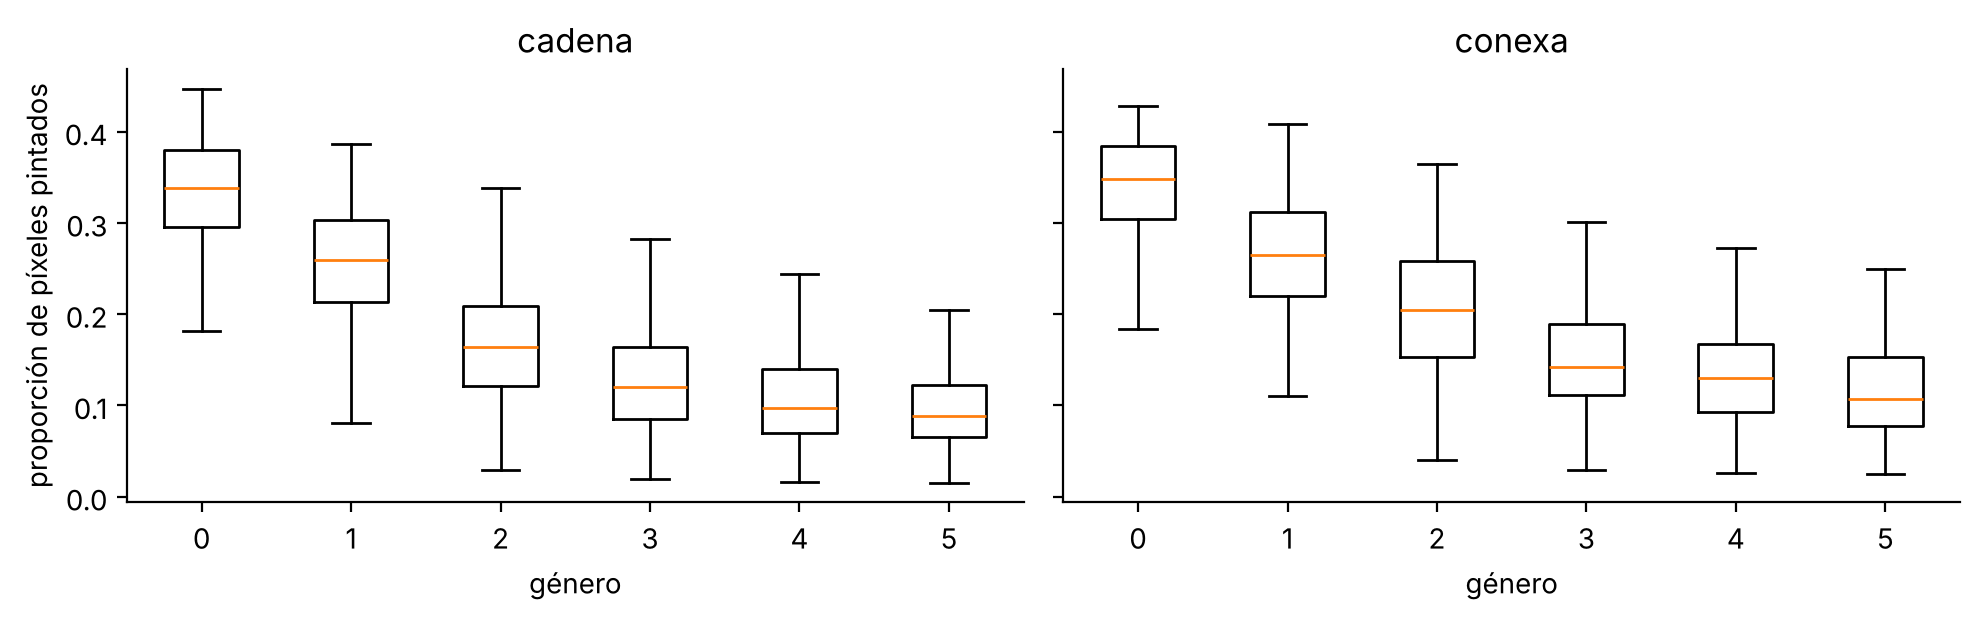

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)  # un panel por dataset
for ax, variant in zip(axes, ("cadena", "conexa")):  # recorre los dos datasets
    frame = manifests[variant][manifests[variant]["split"] == "train"]  # superficies de train
    images, labels, _ = D.fixed_views(frame, clouds[variant], views=1, seed=11)  # una vista fija por superficie
    values = D.ink(images)  # tinta de cada imagen
    ax.boxplot([values[labels.numpy() == g] for g in range(6)], showfliers=False)  # una caja por género
    ax.set_xticklabels(range(6))  # etiquetas del eje x de 0 a 5
    ax.set_xlabel("género")  # nombre del eje x
    ax.set_title(variant)  # nombre del dataset
    ax.spines[["top", "right"]].set_visible(False)  # quita los bordes de arriba y de la derecha
axes[0].set_ylabel("proporción de píxeles pintados")  # nombre del eje y
plt.tight_layout()  # ajusta los espacios
plt.show()  # muestra la figura

## Qué queda de este cuaderno

- El dataset original etiqueta como género g a g toros sueltos. Su χ medido es 0, no 2 − 2g.
- El dataset `conexa` corrige eso: las 210 familias son una sola pieza cerrada con χ = 2 − 2g, y eso se comprueba en cada familia al generarla y en los tests.
- Las dos versiones comparten etiquetas, deformaciones, tamaños y split, así que se pueden comparar directamente. Eso permite preguntar en el cuaderno 02 si la red cuenta huecos o cuenta piezas.